## ДЗ №1. Метрики и простейшие алгоритмы рекомендаций

In [1]:
import unittest
import numpy as np

class APTest(unittest.TestCase):
    def run(self, ap):
        gt_items = np.asarray([2, 4, 5, 10])
        predictions_1 = np.asarray([1, 2, 3, 4, 5])
        predictions_2 = np.asarray([10, 5, 2, 4, 3])
        predictions_3 = np.asarray([1, 3, 6, 7, 8])
        predictions_4 = np.asarray([11, 12, 13, 14, 15, 16, 2, 4, 5, 10])
        predictions_5 = np.asarray([2, 11, 12, 13, 14, 15, 4, 5, 10, 16])
        self.assertTrue(np.allclose(ap(gt_items, predictions_1), (1. / 2 + 2. / 4 + 3. / 5) / 4))
        self.assertTrue(np.allclose(ap(gt_items, predictions_2), 1.0))
        self.assertTrue(np.allclose(ap(gt_items, predictions_3), 0.0))
        self.assertTrue(np.allclose(ap(gt_items, predictions_4), (1. / 7 + 2. / 8 + 3. / 9 + 4. / 10) / 4))
        self.assertTrue(np.allclose(ap(gt_items, predictions_5), (1. + 2. / 7 + 3. / 8 + 4. / 9) / 4))

        thresholds = [1, 2, 3, 4, 5]
        values = [
            0.0,
            1. / 2 / 2,
            1. / 2 / 3,
            (1. / 2 + 2. / 4) / 4,
            (1. / 2 + 2. / 4 + 3. / 5) / 4
        ]
        for at, val in zip(thresholds, values):
            self.assertTrue(np.allclose(np.asarray(ap(gt_items, predictions_1, at)), val))

class RRTest(unittest.TestCase):
    def run(self, rr):
        gt_items = np.asarray([2, 4, 5, 10])
        predictions_1 = np.asarray([1, 2, 3, 4, 5])
        predictions_2 = np.asarray([10, 5, 2, 4, 3])
        predictions_3 = np.asarray([1, 3, 6, 7, 8])
        self.assertTrue(np.allclose(rr(gt_items, predictions_1), 1. / 2))
        self.assertTrue(np.allclose(rr(gt_items, predictions_2), 1.))
        self.assertTrue(np.allclose(rr(gt_items, predictions_3), 0.0))

        thresholds = [1, 2, 3, 4, 5]
        values = [0.0, 1. / 2, 1. / 2, 1. / 2, 1. / 2]
        for at, val in zip(thresholds, values):
            self.assertTrue(np.allclose(np.asarray(rr(gt_items, predictions_1, at)), val))

class HRTest(unittest.TestCase):
    def run(self, hr):
        gt_items = np.asarray([2, 4, 5, 10])
        predictions_1 = np.asarray([1, 2, 3, 4, 5])
        predictions_2 = np.asarray([10, 5, 2, 4, 3])
        predictions_3 = np.asarray([1, 3, 6, 7, 8])
        self.assertTrue(np.allclose(hr(gt_items, predictions_1), 1))
        self.assertTrue(np.allclose(hr(gt_items, predictions_2), 1))
        self.assertTrue(np.allclose(hr(gt_items, predictions_3), 0))

        thresholds = [1, 2, 3]
        values = [0, 1, 1]
        for at, val in zip(thresholds, values):
            self.assertTrue(np.allclose(np.asarray(hr(gt_items, predictions_1, at)), val))

def run_tests(*funcs):
    for cls, func in zip([APTest, RRTest, HRTest], funcs):
        cls().run(func)

In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from tqdm.auto import tqdm
from typing import List, Optional

%matplotlib inline

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## О задании

В этой работе мы посмотрим на то, как работают самые простые модели для рекомендаций. Как правило, они не требуют построения специальных моделей, но даже так оказываются полезны в качестве бейзлайна. Попробуем сделать предсказания с помощью EASE. Это тоже довольно простой подход, но не стоит забывать, что сложные модели могут оказаться не лучшим выбором в условиях большого количества данных. Посчитаем метрики, построим графики и подумаем, насколько хорошо эти модели вообще решают поставленную задачу.

Мы будем работать с датасетом по рекомендации фильмов от Kion MTS, который был дан для соревнования. Сперва нужно его предобработать, эта часть повторяет то, что было на семинаре.

Датасет необходимо скачать: https://ods.ai/competitions/competition-recsys-21/data

Оттуда нужны файлы `interactions.csv` и `items.csv`

Каждое задание весит **1 балл**, если выполнено полностью и без ошибок, **0 баллов** ставится при наличии хотя бы 1 ошибки. Максимальная оценка - **10 баллов**. Шаблоны функций и классов можно менять по своему усмотрению.

In [4]:
df = pd.read_csv('/content/drive/MyDrive/Магистратура/2 курс/RecSys/interactions.csv').iloc[:-1]
df.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


In [5]:
df['last_watch_dt'] = (pd.to_datetime(df['last_watch_dt']) - pd.to_datetime(df['last_watch_dt']).min())
df['last_watch_dt'] = df.last_watch_dt.apply(lambda x: int(str(x).split()[0]))
df.sample(5)

,user_id,item_id,last_watch_dt,total_dur,watched_pct
101795,101755,4436,136,7359,84.0
4677339,192642,13865,91,7625,100.0
3297101,201178,4685,136,7244,100.0
914806,805285,9728,137,3745,55.0
1132229,633936,10077,75,13,0.0


Сделаем разбиение по времени

<Axes: >

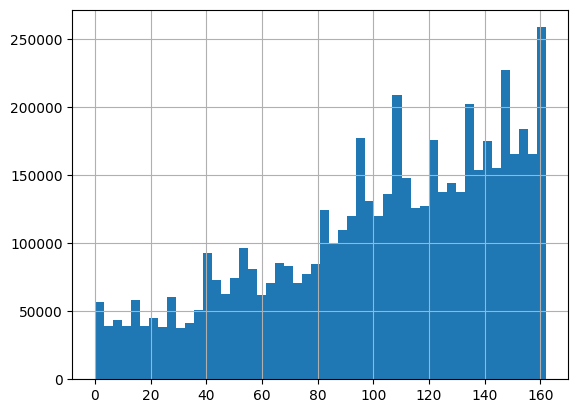

In [6]:
df.last_watch_dt.hist(bins=50)

In [7]:
train_df = df.loc[(df.last_watch_dt < 160-7)].copy()
test_df = df.loc[(df.last_watch_dt >= 160-7)].copy()

train_users = train_df.user_id.unique()
test_users = test_df.user_id.unique()

all_included = np.intersect1d(train_users, test_users)

print('число людей и там и там: ', all_included.shape[0])
print('число людей всего:', train_users.shape[0])

число людей и там и там:  134670
число людей всего: 880449


In [8]:
len(set(test_users) - set(train_users)) / len(test_users)

0.37768022181146027

И переведём всё к соединённому датасету:

In [9]:
n_users = 10000

all_included = np.random.choice(all_included, size=n_users, replace=False)

train_df = train_df.loc[train_df.user_id.isin(all_included)].copy()
test_df = test_df.loc[test_df.user_id.isin(all_included)].copy()

assert train_df.last_watch_dt.max() < test_df.last_watch_dt.min()
assert train_df.user_id.nunique() == n_users
assert test_df.user_id.nunique() == n_users

In [10]:
train_df.head()

,user_id,item_id,last_watch_dt,total_dur,watched_pct
69,804607,5220,120,171,0.0
87,379585,9070,151,2301,35.0
123,514235,8391,147,3570,57.0
228,174320,9728,130,21379,100.0
265,294253,13865,102,4060,64.0


In [11]:
train_grouped = train_df.groupby('user_id').apply(
    lambda x: [(t1, t2) for t1, t2 in sorted(zip(x.item_id,
                                                 x.last_watch_dt), key=lambda x: x[1])]
).reset_index()
train_grouped.rename({0:'train_interactions'}, axis=1, inplace=True)

test_grouped = test_df.groupby('user_id').apply(
    lambda x: [(t1, t2) for t1, t2 in sorted(zip(x.item_id,
                                                         x.last_watch_dt), key=lambda x: x[1])]
).reset_index()
test_grouped.rename({0:'test_interactions'}, axis=1, inplace=True)

train_grouped.head()

/tmp/ipykernel_1228/1105526701.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  train_grouped = train_df.groupby('user_id').apply(
/tmp/ipykernel_1228/1105526701.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  test_grouped = test_df.groupby('user_id').apply(


,user_id,train_interactions
0,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]"
1,259,"[(13865, 109), (10440, 110), (9194, 110), (144..."
2,531,"[(3784, 133), (13865, 134), (4151, 134), (3734..."
3,565,"[(3734, 114), (15297, 114), (4151, 146)]"
4,590,"[(4030, 30), (4359, 33), (16346, 56), (14461, ..."


In [12]:
joined = train_grouped.merge(test_grouped)
joined.head()

,user_id,train_interactions,test_interactions
0,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]","[(15297, 157)]"
1,259,"[(13865, 109), (10440, 110), (9194, 110), (144...","[(10772, 153), (10770, 153), (1769, 158), (458..."
2,531,"[(3784, 133), (13865, 134), (4151, 134), (3734...","[(14488, 161)]"
3,565,"[(3734, 114), (15297, 114), (4151, 146)]","[(4260, 160)]"
4,590,"[(4030, 30), (4359, 33), (16346, 56), (14461, ...","[(10440, 160)]"


In [13]:
np.random.seed(777)

class Random:

    def __init__(self):

        self.trained = False

    def fit(self, df, col='train_interactions'):

        items = set()
        for _, row in df.iterrows():
            for item, _ in row[col]:
                items.add(item)

        self.items = list(items)
        self.trained = True

    def predict(self, df, topn=10):
        assert self.trained
        return [np.random.choice(self.items, replace=False, size=topn)]*len(df)


random = Random()
random.fit(joined)

joined['random_recs'] = random.predict(joined, topn=3)
joined.head()

,user_id,train_interactions,test_interactions,random_recs
0,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]","[(15297, 157)]","[14810, 10704, 16034]"
1,259,"[(13865, 109), (10440, 110), (9194, 110), (144...","[(10772, 153), (10770, 153), (1769, 158), (458...","[14810, 10704, 16034]"
2,531,"[(3784, 133), (13865, 134), (4151, 134), (3734...","[(14488, 161)]","[14810, 10704, 16034]"
3,565,"[(3734, 114), (15297, 114), (4151, 146)]","[(4260, 160)]","[14810, 10704, 16034]"
4,590,"[(4030, 30), (4359, 33), (16346, 56), (14461, ...","[(10440, 160)]","[14810, 10704, 16034]"


**Задание №1. Метрики и бейзлайны**

Добавьте реализацию метрик AP, RR, HR, их усреднённые версии по $U$ мы посчитаем ниже, если следовать коду с семинара, поэтому формулы немного отличаются. За имплементацию с циклами балл будет снижаться, векторизуйте! ( ͡° ͜ʖ ͡°)

$$
AP_u@k = \frac{1}{\min(k, n_u)} \sum_{i=1}^k r_u(i) p_u@i
$$
$$
p_u@k = \dfrac{1}{k}\sum_{j=1}^k r_u(j)
$$
$$
RR@k = \dfrac{1}{\text{rank}_i@k}
$$
$$
HR@k = [\exists \ y_i = 1 \ \text{among k preds}]
$$


*   $n_u$ - число айтемов, с которыми взаимодействовал юзер $u$
*   $y_i$ - релевантно ли $i$-ое предсказание, $y_i \in \{0,1\}$
* $\text{rank}_i@k$ - позиция первого релеваннтого айтема среди первых $k$ предсказаний
* HR@k - среди первых $k$ предсказаний есть хотя бы одно релевантное

Считайте, что если `topn` не задано, то берётся всегда $n_u$.

In [14]:
def ap_metric(
    gt_items: List[int],
    predictions: List[int],
    topn: Optional[int]=None
):
    if len(predictions) == 0:
        return 0

    if (not topn) or (topn > len(predictions)):
        topn = len(predictions)

    r = np.isin(predictions, gt_items).astype('float')[:topn]
    p_k = np.cumsum(r) / np.arange(1, len(r) + 1)
    return (r * p_k).sum() / min(topn, len(gt_items))

def rr_metric(
    gt_items: List[int],
    predictions: List[int],
    topn: Optional[int]=None
):
    if len(predictions) == 0:
        return 0

    if (not topn) or (topn > len(predictions)):
        topn = len(predictions)

    r = np.isin(predictions, gt_items).astype('float')[:topn]
    if not r.any():
        return 0
    return 1 / (np.argmax(r) + 1)

def hr_metric(
    gt_items: List[int],
    predictions: List[int],
    topn: Optional[int]=None
):
    if len(predictions) == 0:
        return 0

    if (not topn) or (topn > len(predictions)):
        topn = len(predictions)

    r = np.isin(predictions, gt_items).astype('float')[:topn]
    return float(r.any())


Для вашего удобства в файле `metric_tests.py` есть тесты, но хардкодить их, разумеется, не стоит.

In [15]:
run_tests(ap_metric, rr_metric, hr_metric)

В следующей ячейке код, который считает и усредняет метрики по юзерам. Он взят с семинара, при желании можно его тоже модифицировать, например, векторизовать.

In [16]:
def evaluate_recommender(df, model_preds, gt_col='test_interactions', topn=None):

    metric_values = []

    for idx, row in df.iterrows():
        gt_items = [x[0] for x in row[gt_col]]
        predictions = row[model_preds]

        ap = ap_metric(gt_items, predictions, topn)
        rr = rr_metric(gt_items, predictions, topn)
        hr = hr_metric(gt_items, predictions, topn)

        metric_values.append((ap, rr, hr))

    return {'map': np.mean([x[0] for x in metric_values]),
            'mrr': np.mean([x[1] for x in metric_values]),
            'hr': np.mean([x[2] for x in metric_values])}

Если вы всё сделали правильно, рандомные предсказания должны дать хоть какое-то качество, но не очень большое.

In [17]:
evaluate_recommender(joined, model_preds='random_recs')

{'map': np.float64(5e-05),
 'mrr': np.float64(0.00015),
 'hr': np.float64(0.0003)}

In [18]:
class TopPopular:

    def __init__(self):

        self.trained = False

    def fit(self, df, col='train_interactions'):

        counts = {}
        for _, row in df.iterrows():
            for item, _ in row[col]:
                if item in counts:
                    counts[item] += 1
                else:
                    counts[item] = 1

        counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)

        self.recommenations = [x[0] for x in counts]
        self.trained = True

    def predict(self, df, topn=10)  -> List[np.ndarray]:

        assert self.trained
        return [self.recommenations[:topn]]*len(df)


toppop = TopPopular()
toppop.fit(joined)

joined['toppopular_recs'] = toppop.predict(joined)
joined.head()

,user_id,train_interactions,test_interactions,random_recs,toppopular_recs
0,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]","[(15297, 157)]","[14810, 10704, 16034]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
1,259,"[(13865, 109), (10440, 110), (9194, 110), (144...","[(10772, 153), (10770, 153), (1769, 158), (458...","[14810, 10704, 16034]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
2,531,"[(3784, 133), (13865, 134), (4151, 134), (3734...","[(14488, 161)]","[14810, 10704, 16034]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
3,565,"[(3734, 114), (15297, 114), (4151, 146)]","[(4260, 160)]","[14810, 10704, 16034]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."
4,590,"[(4030, 30), (4359, 33), (16346, 56), (14461, ...","[(10440, 160)]","[14810, 10704, 16034]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ..."


Самые популярные предсказания должны показать более высокое качество.

In [19]:
evaluate_recommender(joined, model_preds='toppopular_recs')

{'map': np.float64(0.06705439939216427),
 'mrr': np.float64(0.12035944444444445),
 'hr': np.float64(0.2747)}

**Задание №2. Рекомендации в окне**

Здесь необходимо переделать метод рекомендации по популярности так, что популярность считается только за какое-то более свежее временное окно. Под окном подразумевается какой-то временной промежуток, например, ближайший месяц. Соответственно, всё что за его пределами, не учитывается.

In [20]:
from datetime import timedelta

In [21]:
class TopPopularWeighted(TopPopular):

    def __init__(self, min_window=2):
        super().__init__()
        self.min_window = min_window

    def fit(self, df, col='train_interactions'):
        # максимальное значение времени среди всех взаимодействий
        now = max(d for _, row in df.iterrows() for _, d in row[col])
        window_start = now - self.min_window

        # считаем популярность только внутри окна
        counts = {}
        for _, row in df.iterrows():
            for item, d in row[col]:
                if d < window_start:
                    continue
                counts[item] = counts.get(item, 0) + 1

        counts = sorted(counts.items(), key=lambda x: x[1], reverse=True)
        self.recommenations = [x[0] for x in counts]
        self.trained = True

    def predict(self, df, topn=10) -> list:
        assert self.trained
        return [self.recommenations[:topn]] * len(df)

toppopweighted = TopPopularWeighted()
toppopweighted.fit(joined)

joined['toppopweighted_recs'] = toppopweighted.predict(joined)
joined.head()

,user_id,train_interactions,test_interactions,random_recs,toppopular_recs,toppopweighted_recs
0,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]","[(15297, 157)]","[14810, 10704, 16034]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 15297, 9728, 7793, 13865, 341, 4151, 1..."
1,259,"[(13865, 109), (10440, 110), (9194, 110), (144...","[(10772, 153), (10770, 153), (1769, 158), (458...","[14810, 10704, 16034]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 15297, 9728, 7793, 13865, 341, 4151, 1..."
2,531,"[(3784, 133), (13865, 134), (4151, 134), (3734...","[(14488, 161)]","[14810, 10704, 16034]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 15297, 9728, 7793, 13865, 341, 4151, 1..."
3,565,"[(3734, 114), (15297, 114), (4151, 146)]","[(4260, 160)]","[14810, 10704, 16034]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 15297, 9728, 7793, 13865, 341, 4151, 1..."
4,590,"[(4030, 30), (4359, 33), (16346, 56), (14461, ...","[(10440, 160)]","[14810, 10704, 16034]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[10440, 15297, 9728, 7793, 13865, 341, 4151, 1..."


Теперь постройте графики зависимости значений трёх метрик (AP@k, RR@k, HR@k) от размера окна.

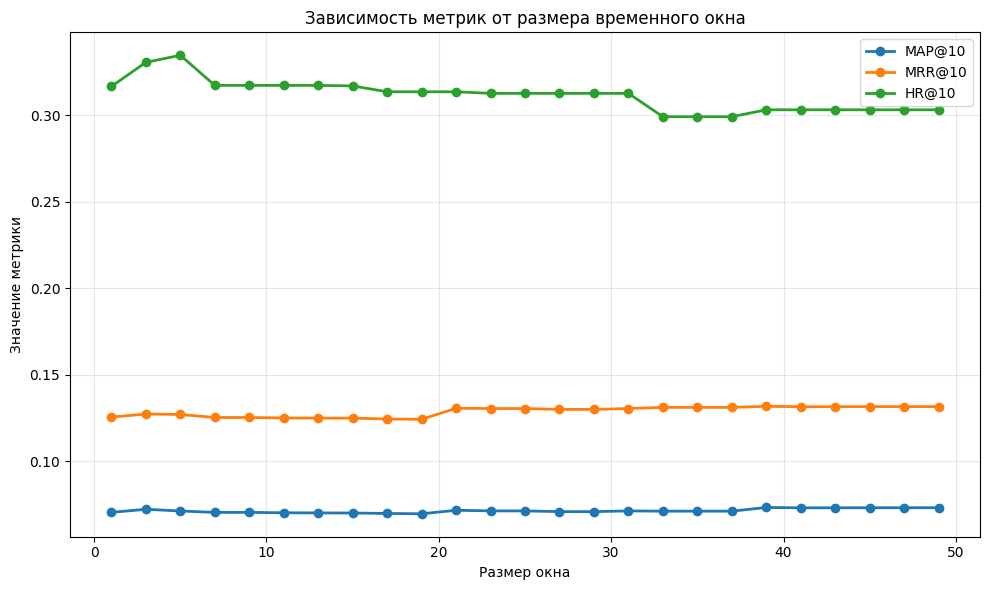

In [22]:
n_window = np.arange(1,50,2)

map_scores = []
mrr_scores = []
hr_scores = []

for n in n_window:
    toppopweighted = TopPopularWeighted(min_window=n)
    toppopweighted.fit(joined)

    joined['toppopweighted_recs'] = toppopweighted.predict(joined)

    temp_metrics = evaluate_recommender(joined, model_preds='toppopweighted_recs')
    map_scores += [temp_metrics['map']]
    mrr_scores += [temp_metrics['mrr']]
    hr_scores += [temp_metrics['hr']]

plt.figure(figsize=(10, 6))
plt.plot(n_window, map_scores, label='MAP@10', marker='o', linewidth=2)
plt.plot(n_window, mrr_scores, label='MRR@10', marker='o', linewidth=2)
plt.plot(n_window, hr_scores,  label='HR@10',  marker='o', linewidth=2)

plt.xlabel('Размер окна')
plt.ylabel('Значение метрики')
plt.title('Зависимость метрик от размера временного окна')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Подумайте и ответьте, как размер окна влияет на качество рекомендаций. Какое значение наилучшее, есть ли у этого разумное объяснение?

**Ответ:** маленькое окно ловит шум (при window=2 в топ попадают случайные всплески), размер окна в диапазоне 5–50 практически не влияет на качество, выбирать конкретное значение стоит по бизнес-логике (например, «последний месяц» = 30)

**Задание №3. Метрики и k.**

Постройте зависимость значений MAP@K, MRR@K, HR@K для метода рекомендации по популярности. Возьмите какие-нибудь k, например, от 1 до 100, переберите значения и покажите на линейном графике.

In [23]:
joined['toppopular_recs'] = toppop.predict(joined, topn=100)

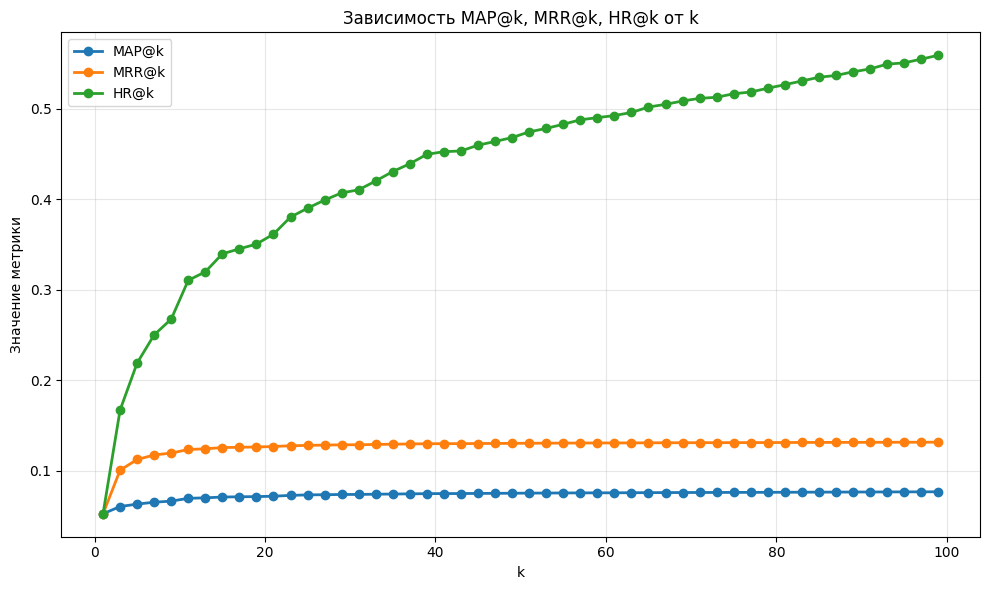

In [24]:
k_values = np.arange(1,100,2)

map_scores = []
mrr_scores = []
hr_scores = []

for k in k_values:
    metrics = evaluate_recommender(joined, model_preds='toppopular_recs', topn=k)

    map_scores += [metrics['map']]
    mrr_scores += [metrics['mrr']]
    hr_scores += [metrics['hr']]

plt.figure(figsize=(10, 6))
plt.plot(k_values, map_scores, label='MAP@k', marker='o', linewidth=2)
plt.plot(k_values, mrr_scores, label='MRR@k', marker='o', linewidth=2)
plt.plot(k_values, hr_scores,  label='HR@k',  marker='o', linewidth=2)

plt.xlabel('k')
plt.ylabel('Значение метрики')
plt.title('Зависимость MAP@k, MRR@k, HR@k от k')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Хорошенько подумайте и ответьте на вопросы ниже.

3.1 Какие из метрик являются монотонными функциями по top-K? Объясните, почему они являются монотонными?

**Ответ:**
HR, MRR и MAP монотонно не убывают, потому что при удлинении списка уже найденные релевантные товары никуда не исчезают и могут только добавиться новые.

---

3.2 Объясните по каждой метрике, как можно интерпретировать ее график? То есть, что можно сказать про связь изменения метрики c возможными пользовательскими сценариями, например,скроллингом ленты новостей.

**Ответ:**
HR показывает, какой длины ленту нужно показать пользователю, чтобы он нашёл хоть что-то нужное, MRR — как быстро он наткнётся на первый подходящий товар (быстро растёт до первых десяти позиций и дальше почти не меняется), а MAP — сколько всего релевантного он соберёт за всю ленту, что важно там, где нужна полнота подборки, а не скорость.

---

3.3 Как вы думаете, почему графики выглядят именно так? Должны ли они возрастать/убывать, от чего это может зависеть? (Тут вам может помочь дополнительный анализ данных)

**Ответ:**
Все метрики растут, потому что каждая новая позиция даёт шанс добавить релевантный товар, но у метода популярности топ одинаков для всех и релевантные товары размазаны по длинному хвосту, поэтому прирост медленный и быстро упирается в плато, а MRR после первых десяти позиций почти не меняется, потому что первый релевантный товар в фиксированном топе стоит на одной и той же позиции независимо от длины списка.

**Задание №4. Интерпретация рейтингов**

Возьмите названия фильмов/сериалов из `items.csv`, выделите 5 различных сценариев изменения популярности у фильмов, аргументируйте (например, графиком или статистикой) и проинтерпретируейте их (почему популярность для этого фильма меняется так). Обратите внимание, что надо найти именно разные паттерны изменения вероятностей.

In [25]:
items = pd.read_csv('/content/drive/MyDrive/Магистратура/2 курс/RecSys/items.csv')[['item_id','title']].copy()
items.head()

,item_id,title
0,10711,Поговори с ней
1,2508,Голые перцы
2,10716,Тактическая сила
3,7868,45 лет
4,16268,Все решает мгновение


Пример:

1917


<Axes: >

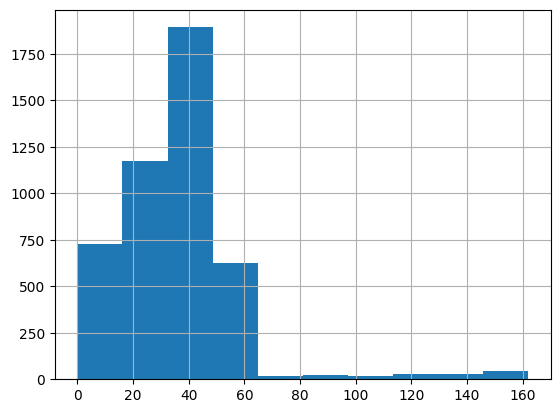

In [26]:
popular_items = df.item_id.value_counts()[:300].index.tolist()
sampled_id = np.random.choice(popular_items)

# это для примера, хотя выцеплять случаи по одному может быть не лучшей идеей
sampled_id = 3402

interactions = df.loc[df.item_id==sampled_id].copy()
name = items.loc[items.item_id==sampled_id].title.values[0]
print(name)
interactions.last_watch_dt.hist()

Фильм 1917 какое-то время набирал популярность, потом видим резкое падение (кстати, с какой даты?). Возможно, это связано с ограничением доступности этого фильма для части пользователей, периодом проката фильма / рекламной кампании или другой причиной.

Добавьте 5 своих примеров ниже. Опишите, как вы их искали.

# Все взаимодействия по дням

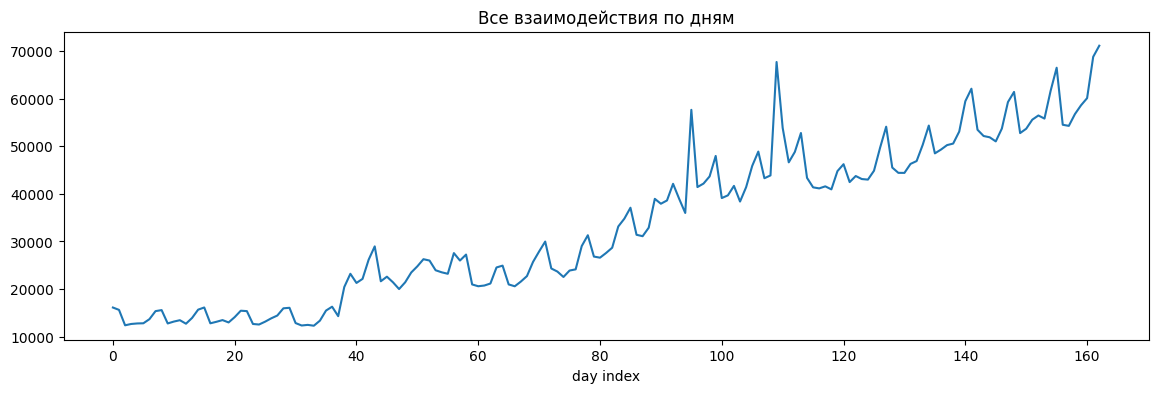

In [27]:
day = df['last_watch_dt']

daily_all = df.groupby(day).size()
daily_all.plot(figsize=(14, 4), title='Все взаимодействия по дням')
plt.xlabel('day index')
plt.show()

# Фильмы которые смотрели только первые 7 дней

In [28]:
stats = df.groupby('item_id').agg(
    first_dt=('last_watch_dt', 'min'),
    last_dt=('last_watch_dt', 'max'),
    n=('item_id', 'size'),
)

daily_item = (
    df.groupby(['item_id', 'last_watch_dt'])
      .size()
      .unstack(fill_value=0)
)

# доля просмотров в первые 7 дней после появления
tmp = df[['item_id', 'last_watch_dt']].merge(stats['first_dt'], on='item_id')
first_week_n = (
    tmp[tmp['last_watch_dt'] < tmp['first_dt'] + 7]
    .groupby('item_id').size()
    .rename('first_week_n')
)
stats = stats.join(first_week_n).fillna({'first_week_n': 0})
stats['share_first_week'] = stats['first_week_n'] / stats['n']

# фильтр по объёму и длительности
stats = stats[stats['n'] > 300]
stats['lifetime'] = stats['last_dt'] - stats['first_dt'] + 1

# пик и его позиция
peak_pos = daily_item.idxmax(axis=1)
peak_val = daily_item.max(axis=1)
stats['peak_pos'] = peak_pos.reindex(stats.index)
stats['peak_val'] = peak_val.reindex(stats.index)
stats['peak_offset'] = stats['peak_pos'] - stats['first_dt']

data_end = df['last_watch_dt'].max()

In [29]:
from scipy.signal import find_peaks, peak_prominences

# затухание: среднее за 14 дней после пика / высота пика
def decay_ratio(row, days=14):
    s = daily_item.loc[row.name]
    p = int(row['peak_pos'] - s.index[0])
    peak = s.values[p]
    window = s.values[p + 1: p + 1 + days]
    if peak == 0 or len(window) == 0:
        return np.nan
    return window.mean() / peak

stats['decay_ratio'] = stats.apply(decay_ratio, axis=1)

# поздний рост: активность в последней трети vs в первой
def late_boost(row):
    s = daily_item.loc[row.name]
    n = len(s)
    if n < 30:
        return np.nan
    early = s.values[:n // 3].mean()
    late = s.values[2 * n // 3:].mean()
    return late / early if early > 0 else np.nan

stats['late_boost'] = stats.apply(late_boost, axis=1)

# тренд: нормированный наклон линейной регрессии
def trend_strength(series):
    x = np.arange(len(series))
    if len(series) < 10 or series.sum() == 0:
        return np.nan
    slope = np.polyfit(x, series.values, 1)[0]
    return slope / (series.mean() + 1e-9)

stats['trend'] = daily_item.apply(trend_strength, axis=1)

# число выделенных пиков через prominence
def n_prominent_peaks(series, min_prom_ratio=0.3, min_dist=14):
    s = series.rolling(3, min_periods=1).mean().values
    peaks, _ = find_peaks(s, distance=min_dist)
    if len(peaks) == 0:
        return 0
    prom = peak_prominences(s, peaks)[0]
    thresh = prom.max() * min_prom_ratio
    return int((prom >= thresh).sum())

stats['n_peaks'] = daily_item.apply(n_prominent_peaks, axis=1)

In [30]:
# 1. Вспышка и затухание
burst = stats[
    (stats['peak_offset'] <= 14) &
    (stats['peak_val'] > 50) &
    (stats['decay_ratio'] < 0.2) &
    (stats['lifetime'] > 60)
]

# 2. Поздний старт (item появился в последние 15% периода наблюдения)
late_start = stats[
    (stats['first_dt'] > data_end * 0.85) &
    (stats['lifetime'] < 30)
]

# 3. Медленный разгон: слабый старт + поздний пик + активный поздний рост
slow = stats[
    (stats['share_first_week'] < 0.05) &
    (stats['peak_offset'] > stats['lifetime'] * 0.4) &
    (stats['late_boost'] > 1.5) &
    (stats['lifetime'] > 60) &
    (stats['first_dt'] < data_end * 0.5)
]

# 4. Плато: ровный уровень, слабый тренд, без резких пиков
cv = daily_item.agg(['max', 'median'], axis=1)
plateau = stats[
    (cv['median'].reindex(stats.index) > 5) &
    (cv['max'].reindex(stats.index) / cv['median'].reindex(stats.index) < 3) &
    (stats['trend'].abs() < 0.005)
]

# 5. Повторные всплески: 3+ выделенных пика
multi = stats[stats['n_peaks'] >= 3]

print(f"burst: {len(burst)} | late_start: {len(late_start)} | "
      f"slow: {len(slow)} | plateau: {len(plateau)} | multi: {len(multi)}")

burst: 37 | late_start: 95 | slow: 1087 | plateau: 26 | multi: 1182



[Вспышка и затухание] топ-5:
  id=391    Спарта                                   n=1231 lifetime=100


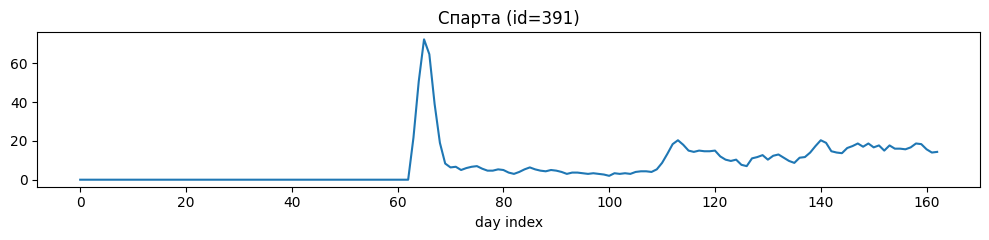

  id=626    Окей, Лекси!                             n=1225 lifetime=140


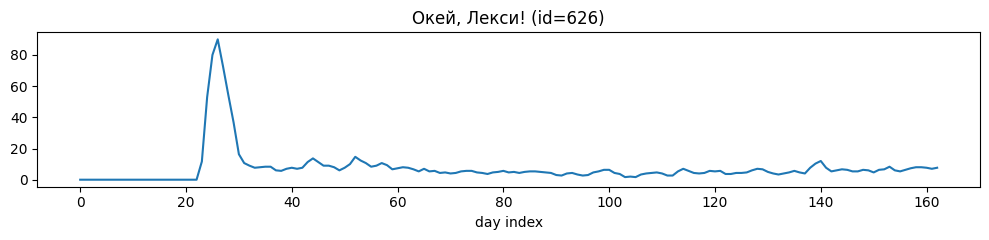

  id=1179   Ограбление с ограничениями               n=2588 lifetime=136


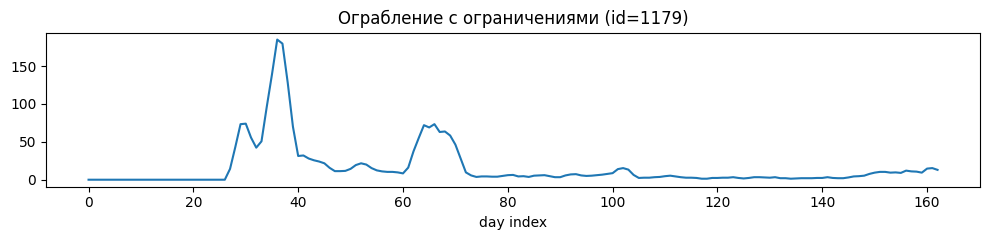

  id=1646   Девушка грез                             n=573 lifetime=111


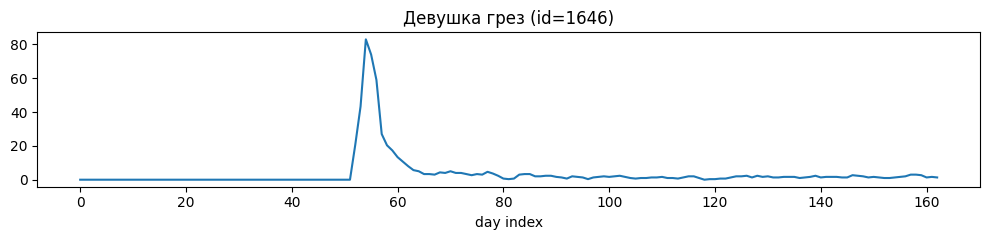

  id=1676   Догвилль                                 n=803 lifetime=114


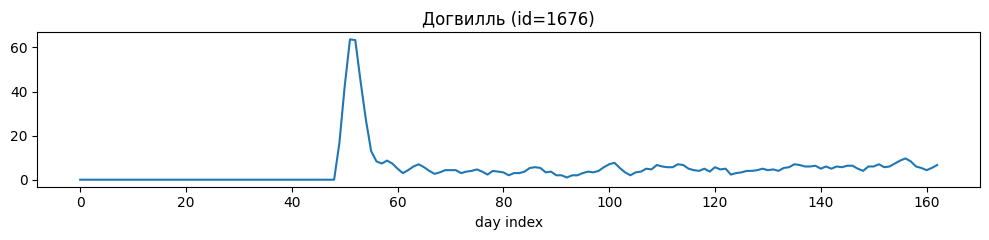


[Поздний старт] топ-5:
  id=89     Закон исключенного третьего, или третьег n=315 lifetime=6


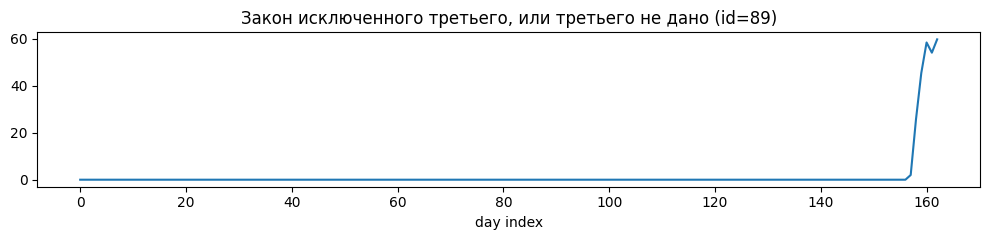

  id=169    Белый шквал                              n=1629 lifetime=19


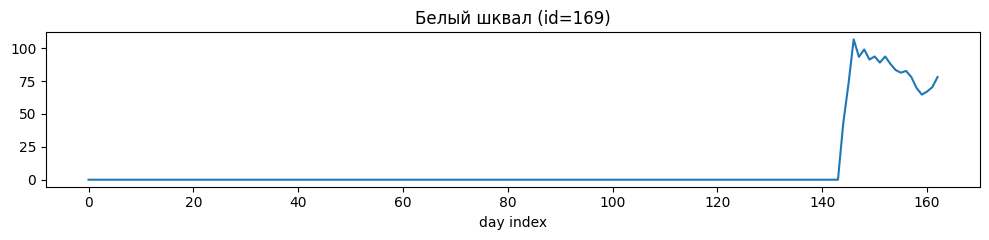

  id=219    Убежать, догнать, влюбиться!             n=598 lifetime=23


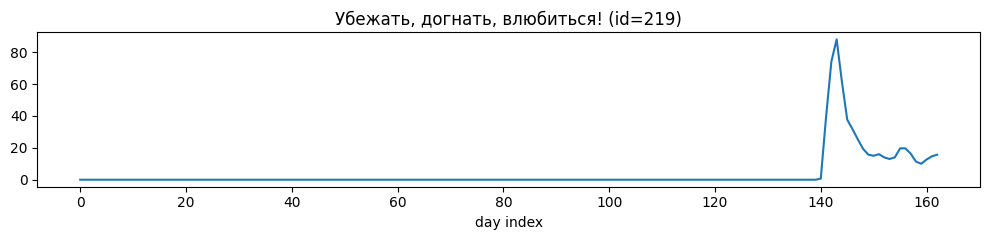

  id=230    Книга моря                               n=700 lifetime=13


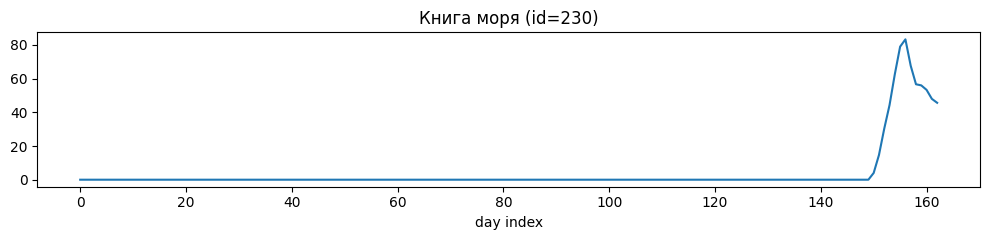

  id=341    Лето - это море                          n=11323 lifetime=15


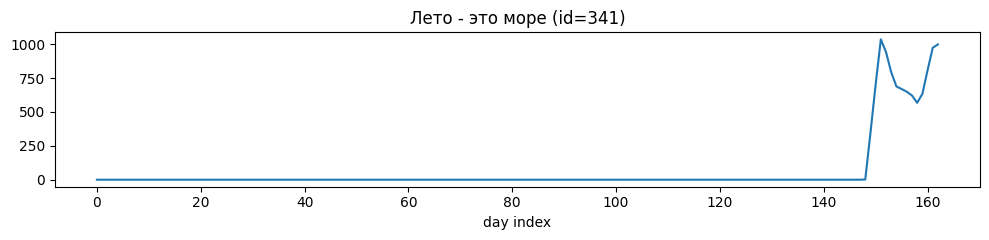


[Медленный разгон] топ-5:
  id=47     Драка в блоке 99                         n=1700 lifetime=162


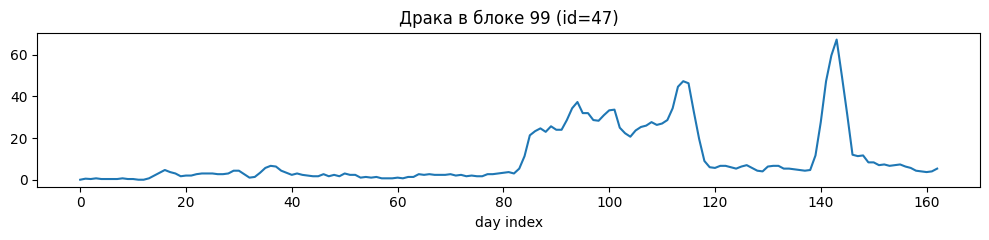

  id=85     Турбо                                    n=1146 lifetime=163


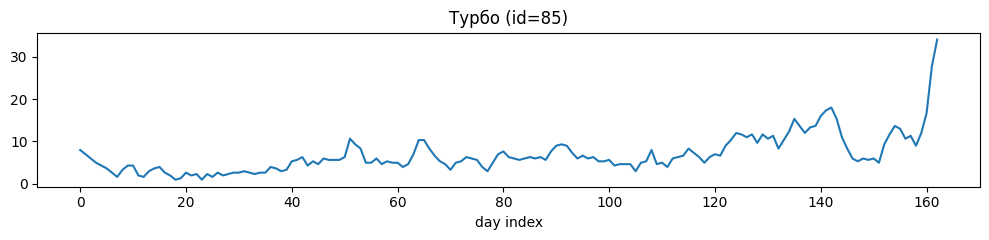

  id=111    Планета обезьян                          n=1997 lifetime=163


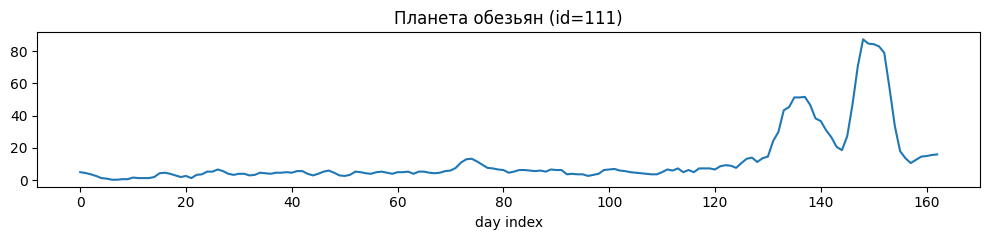

  id=125    Копы в юбках                             n=1823 lifetime=162


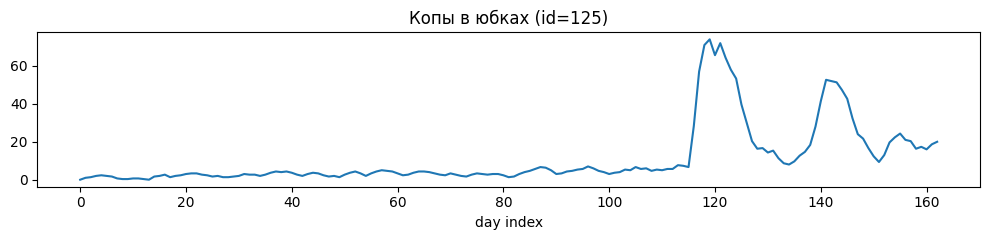

  id=140    Пришельцы в доме                         n=523 lifetime=163


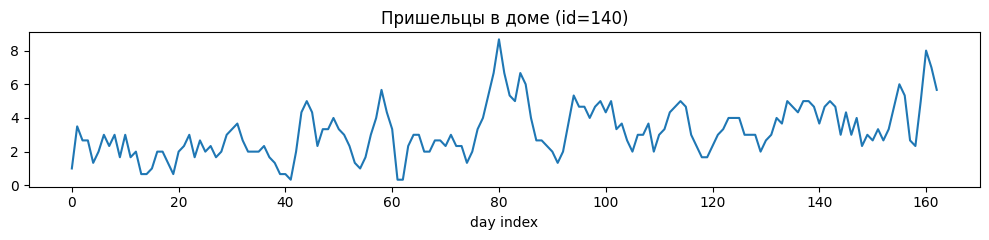


[Долгое плато] топ-5:
  id=237    Хемлок Гроув                             n=1295 lifetime=163


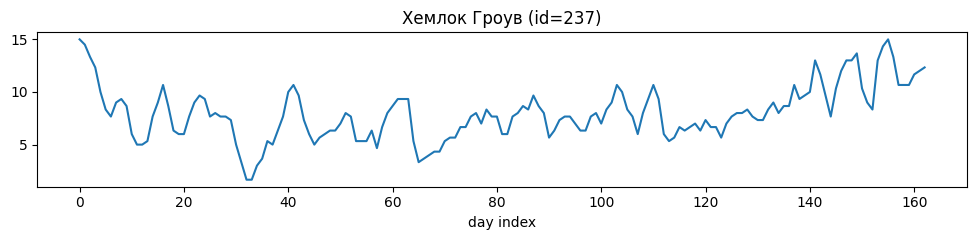

  id=496    Воскресший Эртугрул                      n=6167 lifetime=163


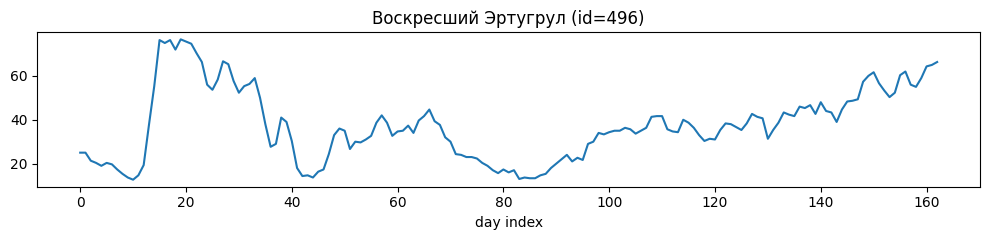

  id=579    Недруги                                  n=1222 lifetime=163


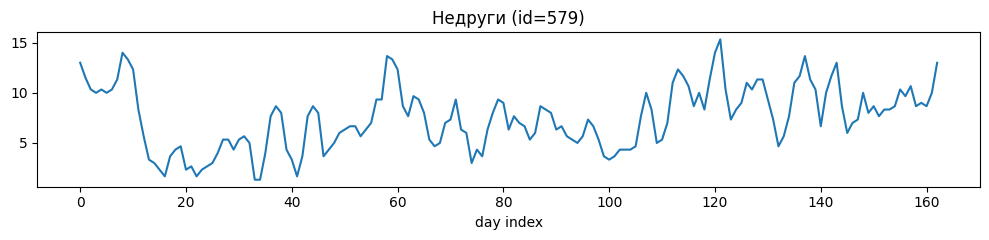

  id=1659   Три богатыря. Ход конем                  n=1086 lifetime=163


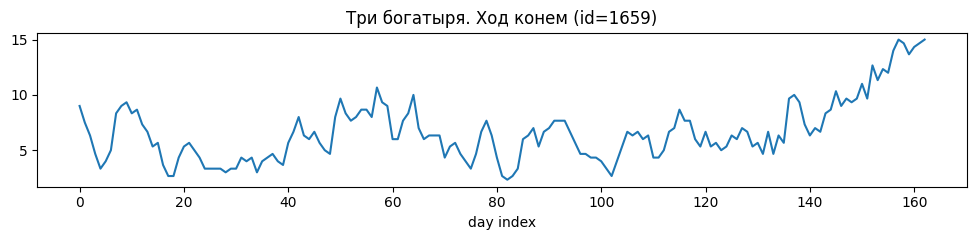

  id=1873   Секс трип                                n=3183 lifetime=163


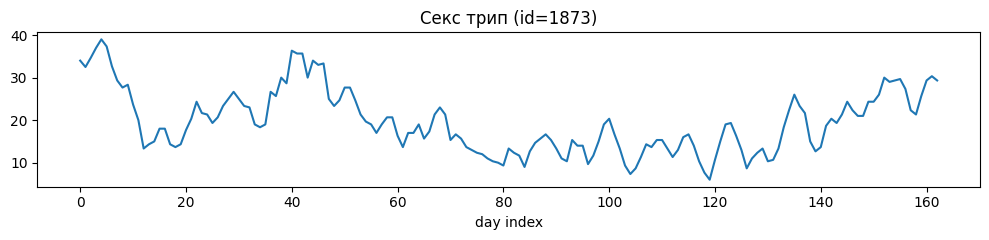


[Повторные всплески] топ-5:
  id=14     Жестокий Стамбул                         n=8517 lifetime=105


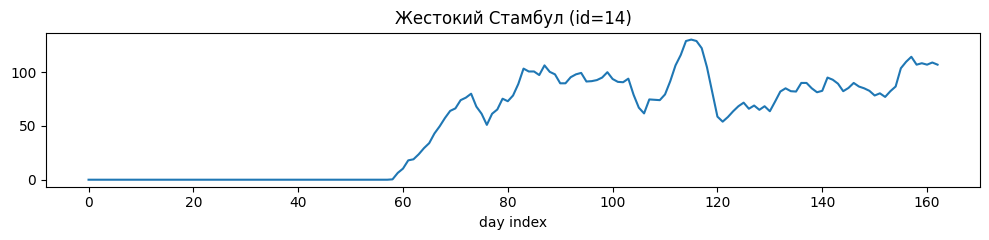

  id=35     Эспен в королевстве троллей              n=602 lifetime=163


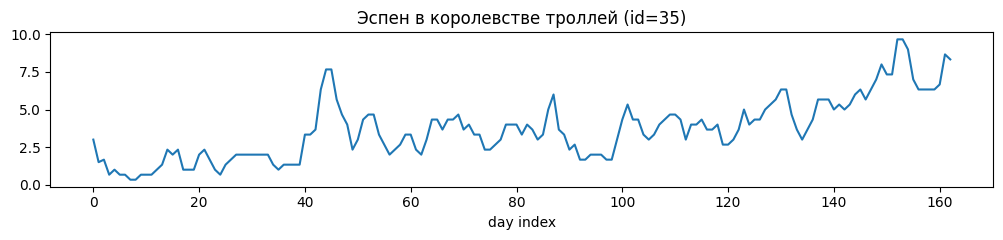

  id=85     Турбо                                    n=1146 lifetime=163


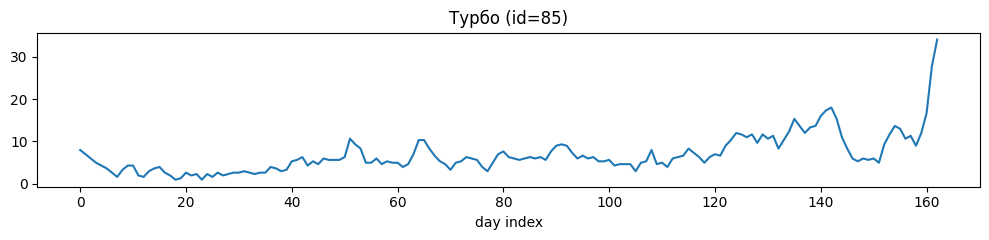

  id=86     7,3 тонны                                n=316 lifetime=163


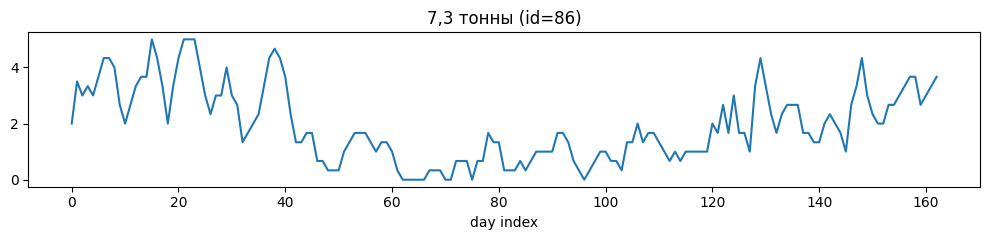

  id=98     Ходячие мертвецы                         n=652 lifetime=163


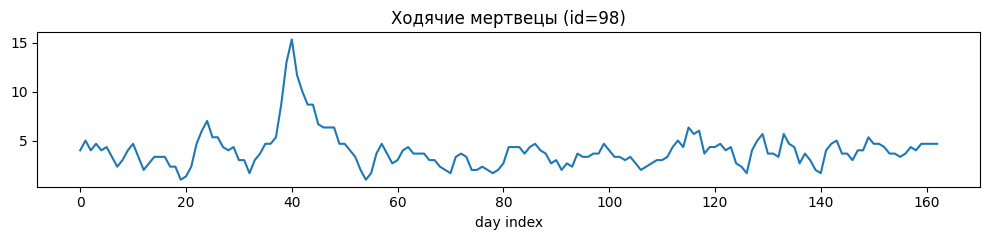

In [31]:
def preview(bucket, name, top=5):
    if len(bucket) == 0:
        print(f"\n[{name}] пусто")
        return
    print(f"\n[{name}] топ-{top}:")
    for iid in bucket.head(top).index:
        title = items.loc[items.item_id == iid, 'title'].values[0]
        row = bucket.loc[iid]
        print(f"  id={iid:<6} {title[:40]:<40} "
              f"n={int(row['n'])} lifetime={int(row['lifetime'])}")
        daily_item.loc[iid].rolling(3, min_periods=1).mean().plot(
            figsize=(10, 2.5), title=f'{title} (id={iid})'
        )
        plt.xlabel('day index')
        plt.tight_layout()
        plt.show()

preview(burst, 'Вспышка и затухание')
preview(late_start, 'Поздний старт')
preview(slow, 'Медленный разгон')
preview(plateau, 'Долгое плато')
preview(multi, 'Повторные всплески')

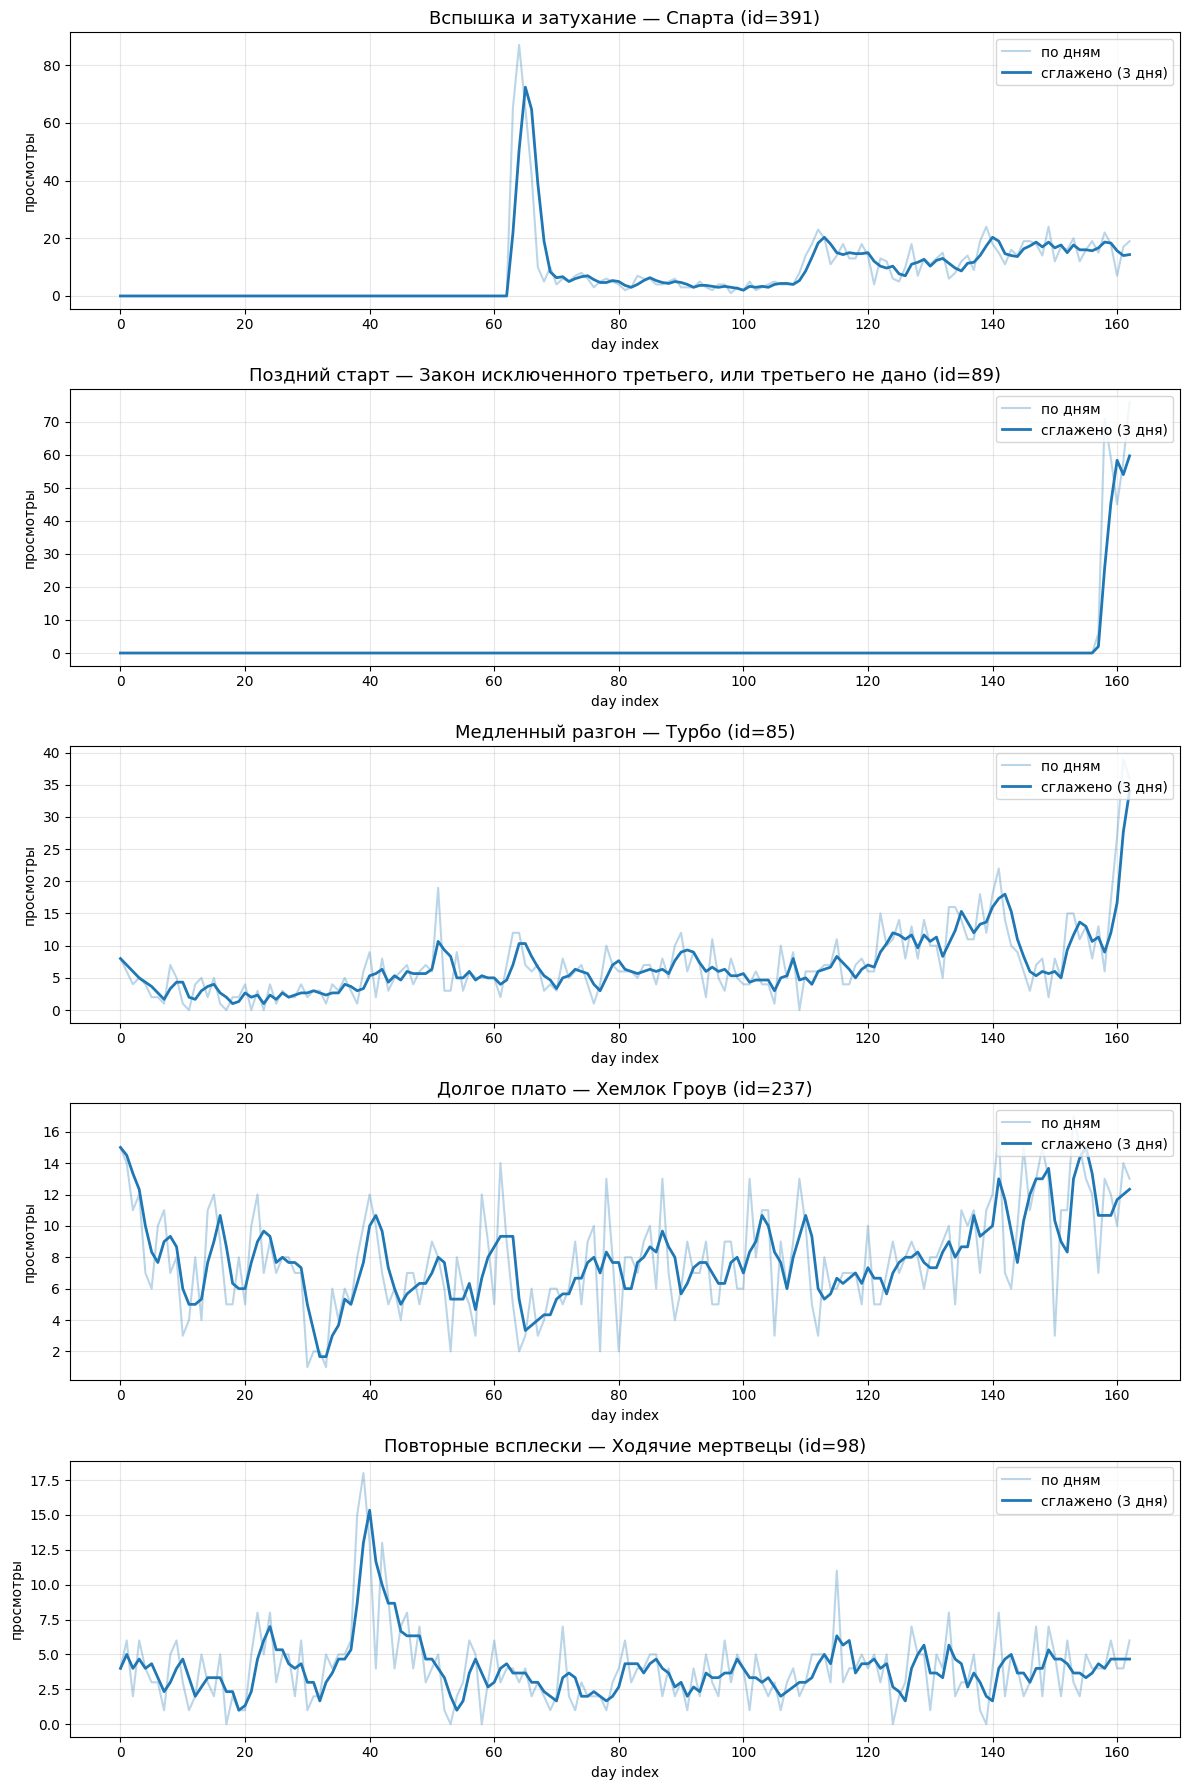

In [32]:
chosen = {
    'Вспышка и затухание': 391,
    'Поздний старт':       89,
    'Медленный разгон':    85,
    'Долгое плато':        237,
    'Повторные всплески':  98,
}

fig, axes = plt.subplots(5, 1, figsize=(12, 18))
for ax, (pattern, iid) in zip(axes, chosen.items()):
    if iid is None:
        ax.set_visible(False)
        continue
    title = items.loc[items.item_id == iid, 'title'].values[0]
    s = daily_item.loc[iid]
    smooth = s.rolling(3, min_periods=1).mean()

    ax.plot(s.index, s.values, alpha=0.3, color='C0', label='по дням')
    ax.plot(smooth.index, smooth.values, color='C0', linewidth=2, label='сглажено (3 дня)')
    ax.set_title(f'{pattern} — {title} (id={iid})', fontsize=13)
    ax.set_xlabel('day index')
    ax.set_ylabel('просмотры')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

**Задание №5. User-item encoding**

Теперь, создайте матрицу интеракций user-item по примеру из семинара. Вам нужно в итоге получить разреженную матрицу (sparse matrix), в которой в качестве строк будут пользователи, в качестве колонок - айтемы. Не забудьте перекодировать пользователей и айтемы через энкодер. В отличие от семинара, оставьте в матрице только юзеров и айтемы, которые встречались в матрице > 4 раз.

Важно: когда вы отфильтруете юзеров на встречаемость > 4 раз, вы удалите какие-то айтемы, которые теперь станут встречаться меньше 5 раз. Поэтому у вас перестанет выполняться второе условие на минимальное число интеракций с айтемом. Тогда вам надо опять отфильтровать айтемы на встречаемость, но это снова может нарушить условие для юзеров. В таком случае, вам надо написать итеративный алгоритм до сходимости, пока требования не будут выполняться в обеих колонках.

In [33]:
def filter_column(df, col, min_freq):
    """
    Filter dataframe, excluding least active users and least popular items.
    Return a copy of the dataframe with at least min_freq entries
    in both users and items
    """
    counters = df[col].value_counts()
    return df[df[col].isin(counters[counters>=min_freq].index)].copy()

def filter_dataframe(df, cols, min_freq=5):
    """
    Filter dataframe by given columns until each of them satisfies
    min_freq condition, guaranteed by filter_columns. Return a copy
    of the dataframe
    """
    df = df.copy()
    len_prev = len(df)
    while True:
        for col in cols:
            df = filter_column(df, col, min_freq)

        if len(df)!=len_prev:
            len_prev = len(df)
        else:
            break

    return df

filtered_train = filter_dataframe(train_df.copy(), ['user_id','item_id'], 5)
filtered_train

,user_id,item_id,last_watch_dt,total_dur,watched_pct
69,804607,5220,120,171,0.0
123,514235,8391,147,3570,57.0
228,174320,9728,130,21379,100.0
265,294253,13865,102,4060,64.0
290,306633,6870,147,6853,92.0
...,...,...,...,...,...
5475862,200870,8636,134,8219,100.0
5476046,567292,9169,140,5897,100.0
5476059,771625,2864,152,901,13.0
5476127,413294,1381,137,16,0.0


In [34]:
# проверяем, что оба условия выполнены
user_counts = filtered_train['user_id'].value_counts()
item_counts = filtered_train['item_id'].value_counts()
print("min user freq:", user_counts.min())
print("min item freq:", item_counts.min())
print("users:", filtered_train.user_id.nunique(),
      "items:", filtered_train.item_id.nunique())

min user freq: 5
min item freq: 5
users: 5949 items: 3163


In [35]:
def df_encode(df):
    item2id = {k:v for v, k in enumerate(df.item_id.unique())}
    user2id = {k:v for v, k in enumerate(df.user_id.unique())}

    id2item = {k:v for v, k in item2id.items()}
    id2user = {k:v for v, k in user2id.items()}

    df['user_id'] = df.user_id.apply(lambda x: user2id[x])
    df['item_id'] = df.item_id.apply(lambda x: item2id[x])
    return df, item2id, user2id, id2item, id2user

filtered_train, item2id, user2id, id2item, id2user = df_encode(filtered_train)
filtered_train.sample(5)

,user_id,item_id,last_watch_dt,total_dur,watched_pct
1889969,815,302,104,307,0.0
4458442,2060,1305,89,6342,100.0
5041004,407,772,93,661,0.0
3957223,1247,211,50,9295,100.0
2157780,33,741,118,3487,67.0


In [36]:
from scipy import sparse as sps

matrix = sps.coo_matrix(
    (np.ones(filtered_train.shape[0]), (filtered_train['user_id'], filtered_train['item_id'])),
    shape=(len(user2id), len(item2id)),
)
matrix

<COOrdinate sparse matrix of dtype 'float64'
	with 108741 stored elements and shape (5949, 3163)>

**Задание №6. Интеракции и частота**

Постройте график зависимости количества айтемов и юзеров от значений (порогов) фильтров на встречаемость в матрице интеракций. То есть, нужно выполнить задание №5 для нескольких значений `min_freq` и построить график зависимости числа оставшихся айтемов и юзеров от этого параметра.

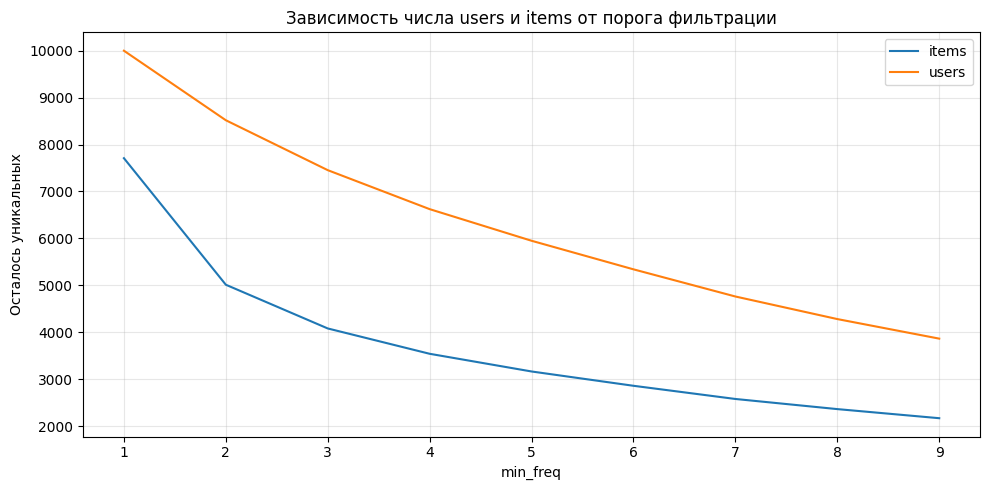

In [37]:
k = np.arange(1,10,1)

items = []
users = []
for i in k:
    filtered_train = filter_dataframe(train_df.copy(), ['user_id','item_id'], i)
    items.append(len(filtered_train['item_id'].unique()))
    users.append(len(filtered_train['user_id'].unique()))

plt.figure(figsize=(10, 5))

plt.plot(k,items, label = 'items')
plt.plot(k,users, label = 'users')
plt.xlabel('min_freq')
plt.ylabel('Осталось уникальных')
plt.title('Зависимость числа users и items от порога фильтрации')
plt.grid(True, alpha=0.3, which='both')
plt.legend()
plt.tight_layout()
plt.show()

**Задание №7. EASE**

Реализуйте EASE, постройте рекомендации для юзеров. Сравните все имплементированные ранее метрики качества с `TopPopular` для некоторого набора k.

Реализацию можно взять из семинара. Можно реализовать по статье https://arxiv.org/pdf/1905.03375.pdf. Можно взять и адаптировать из RecBole https://github.com/RUCAIBox/RecBole.

In [38]:
#%%time

# Обучаем конечную модель
# Мы взяли реализацию из RecBole
#
def fit_ease(X, reg_weight=1000):
    if sps.issparse(X):
        X = X.tocsc()
    else:
        X = sps.csc_matrix(X)

    G = (X.T @ X).toarray()

    diagIndices = np.diag_indices(G.shape[0])
    G[diagIndices] += reg_weight

    P = np.linalg.inv(G)
    B = P / (-np.diag(P))
    B[diagIndices] = 0

    return B

w = fit_ease(matrix)

In [39]:
w.shape

(3163, 3163)

Далее, вам надо реализовать функцию получения предсказаний. У вас есть обученная матрица весов, которую можно использовать для получения предсказаний. Для этого нужно построить вектор интеракций пользователя и умножить его на матрицу весов.

In [40]:
def get_preds(x, item2id, id2item, w,top_n=5):

    user_vector = np.zeros(len(w))
    idx_list = []

    for num in x:
        item = num[0]
        if item in item2id:
            idx = item2id[item]
            idx_list.append(idx)
            user_vector[idx] = 1

    result = user_vector @ w
    result[idx_list] = -np.inf
    top_result = np.argsort(result)[::-1][:top_n]

    decoded = []
    for idx in top_result:
        decoded.append(id2item[idx])

    return decoded

joined['ease_preds'] = joined.train_interactions.apply(lambda x: get_preds(x, item2id, id2item, w, top_n=100))
joined.head()

,user_id,train_interactions,test_interactions,random_recs,toppopular_recs,toppopweighted_recs,ease_preds
0,179,"[(14, 75), (13865, 95), (10440, 95), (9728, 97)]","[(15297, 157)]","[14810, 10704, 16034]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[15297, 9728, 10440, 3734, 13865, 4151, 12192,...","[15297, 3734, 2657, 9996, 4880, 4151, 8636, 14..."
1,259,"[(13865, 109), (10440, 110), (9194, 110), (144...","[(10772, 153), (10770, 153), (1769, 158), (458...","[14810, 10704, 16034]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[15297, 9728, 10440, 3734, 13865, 4151, 12192,...","[4151, 3734, 9996, 4495, 2657, 4880, 12192, 12..."
2,531,"[(3784, 133), (13865, 134), (4151, 134), (3734...","[(14488, 161)]","[14810, 10704, 16034]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[15297, 9728, 10440, 3734, 13865, 4151, 12192,...","[15297, 10440, 9728, 4880, 2657, 9996, 8636, 1..."
3,565,"[(3734, 114), (15297, 114), (4151, 146)]","[(4260, 160)]","[14810, 10704, 16034]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[15297, 9728, 10440, 3734, 13865, 4151, 12192,...","[10440, 4880, 9728, 13865, 142, 2657, 12192, 1..."
4,590,"[(4030, 30), (4359, 33), (16346, 56), (14461, ...","[(10440, 160)]","[14810, 10704, 16034]","[10440, 15297, 9728, 13865, 3734, 4151, 4880, ...","[15297, 9728, 10440, 3734, 13865, 4151, 12192,...","[10440, 13865, 3734, 9728, 6809, 8636, 4495, 1..."


In [41]:
k_values = np.arange(1,100,2)
map = []
mrr = []
hr = []
map_ease = []
mrr_ease = []
hr_ease = []
for k in k_values:

    temp_metrics = evaluate_recommender(joined, model_preds='toppopular_recs', topn=k)
    ease_metrics = evaluate_recommender(joined, model_preds='ease_preds', topn=k)

    map += [temp_metrics['map']]
    mrr += [temp_metrics['mrr']]
    hr += [temp_metrics['hr']]

    map_ease += [ease_metrics['map']]
    mrr_ease += [ease_metrics['mrr']]
    hr_ease += [ease_metrics['hr']]

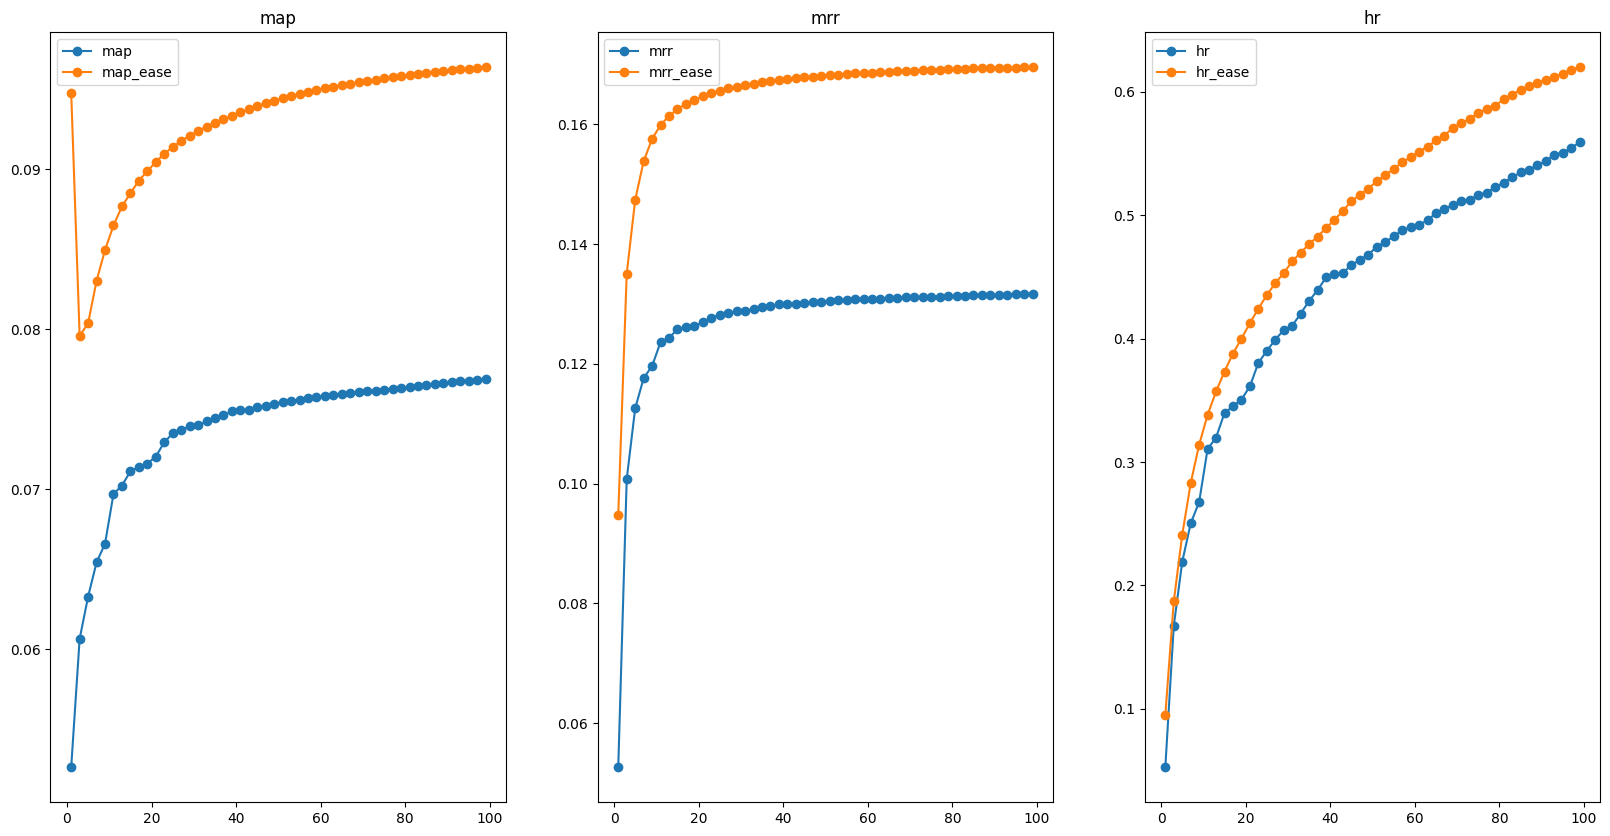

In [42]:
plt.figure(figsize=(20,10))

plt.subplot(1,3,1)
plt.plot(k_values, map, label='map', marker='o')
plt.plot(k_values, map_ease, label='map_ease', marker='o')
plt.title('map')
plt.legend()

plt.subplot(1,3,2)
plt.plot(k_values, mrr, label='mrr', marker='o')
plt.plot(k_values, mrr_ease, label='mrr_ease', marker='o')
plt.title('mrr')
plt.legend()

plt.subplot(1,3,3)
plt.plot(k_values, hr, label='hr', marker='o')
plt.plot(k_values, hr_ease, label='hr_ease', marker='o')
plt.title('hr')
plt.legend()

Сделайте выводы — какой алгоритм работает лучше?

**Ответ:**

EASE обгоняет по всем метрикам и на всех k, причём разрыв растёт с увеличением k. Это ожидаемо: EASE персонализирован, поэтому находит релевантные items и в топе, и в длинном хвосте, тогда как TopPopular показывает всем один и тот же глобальный топ и упирается в потолок.

**Задание №8. Тюнинг**

Переберите различные значения гиперпараметра коэффициента регуляризации у EASE и постройте графики, как в задании №6. Постарайтесь "затюнить" EASE как можно лучше. Возьмите разумное число гиперпараметров - хотя бы штук 20 по логарифмической сетке, либо используйте более хитрые алгоритмы оптимизации.

In [43]:
map = []
mrr = []
hr = []
k = 10

reg_weights = np.logspace(0,5,20)

for reg_weight in reg_weights:
    w = fit_ease(matrix,reg_weight=reg_weight)
    joined['easeweighted_recs'] = joined.train_interactions.apply(lambda x: get_preds(x, item2id, id2item, w, top_n=k))

    ease_metrics = evaluate_recommender(joined, model_preds='easeweighted_recs', topn=k)

    map += [ease_metrics['map']]
    mrr += [ease_metrics['mrr']]
    hr += [ease_metrics['hr']]

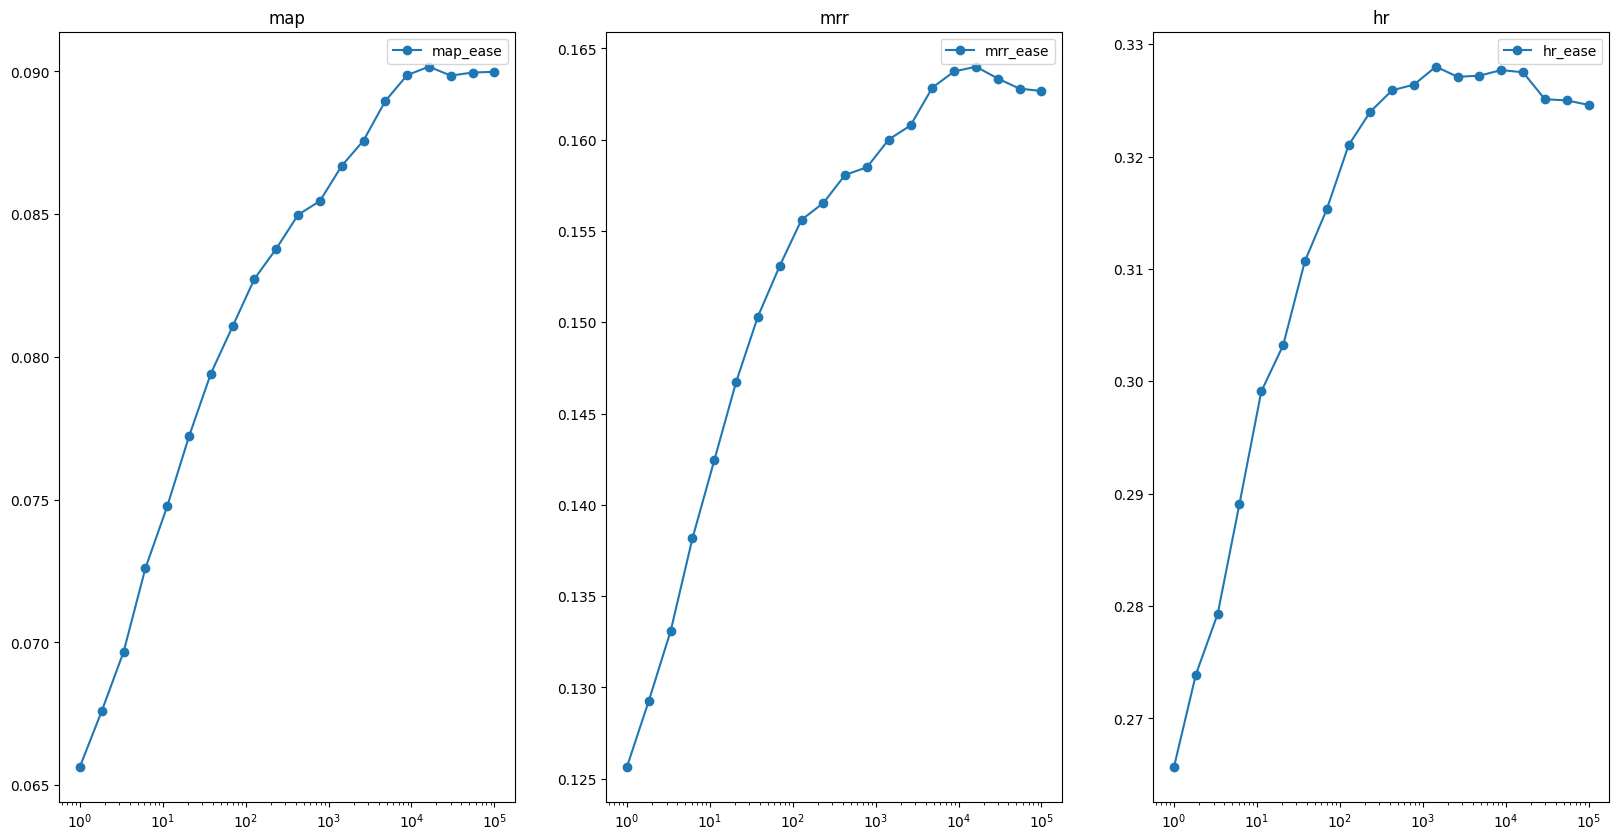

In [44]:
plt.figure(figsize=(20,10))

plt.subplot(1,3,1)
plt.xscale('log')
plt.plot(reg_weights, map, label='map_ease', marker='o')
plt.title('map')
plt.legend()

plt.subplot(1,3,2)
plt.xscale('log')
plt.plot(reg_weights, mrr, label='mrr_ease', marker='o')
plt.title('mrr')
plt.legend()

plt.subplot(1,3,3)
plt.xscale('log')
plt.plot(reg_weights, hr, label='hr_ease', marker='o')
plt.title('hr')
plt.legend()

In [45]:
map_arr = np.array(map)
mrr_arr = np.array(mrr)
hr_arr  = np.array(hr)

def normalize(x):
    rng = x.max() - x.min()
    return (x - x.min()) / rng if rng > 0 else np.zeros_like(x)

score = normalize(map_arr) + normalize(mrr_arr) + normalize(hr_arr)
best_idx = int(np.argmax(score))
best_reg_weight = reg_weights[best_idx]

print(f"Лучший reg_weight (сумма нормированных): {best_reg_weight}")
print(f"MAP={map_arr[best_idx]:.4f}, MRR={mrr_arr[best_idx]:.4f}, HR={hr_arr[best_idx]:.4f}")

Лучший reg_weight (сумма нормированных): 16237.76739188721
MAP=0.0902, MRR=0.1640, HR=0.3275


Ответьте на следующие вопросы:

8.1 Какое значение гиперпараметра является наилучшим?


**Ответ:** Наулучшее значение гиперпараметра = 8858.

8.2 Что еще интересного вы можете сказать по графикам? Может быть, что-то свзяанное с распределением параметров, влиянием на отдельные метрики, скоростью тюнинга?

**Ответ:** После значения гиперпараметра около 10^3 улучшения не происходит.

**Задание №9. EASE и topk**

В лекции №2 говорилось, что качество у EASE растет с ослаблением фильтра на число айтемов. В этом задании постройте кривые метрик качества MAP/MRR/HR в зависимости от topk (например, от 1 до 100 с некоторым шагом), где кривая параметризована минимальным требуемым значением встречаемости user/item (из задания №6). Опишите свои выводы.

Важно: в этом задании линии могут быть мало различимыми, поэтому ваша задача для каждой метрики найти нужный масштаб на каких-то конкретных topk, чтобы линии стали визуально отличимы.

In [46]:
best_reg_weight = 8858

min_freqs = np.arange(1, 10, 1)
k_values = np.arange(1, 101, 2)

results = {}

for min_freq in min_freqs:
    ft = filter_dataframe(train_df.copy(), ['user_id', 'item_id'], min_freq)

    ft, item2id_mf, user2id_mf, id2item_mf, id2user_mf = df_encode(ft.copy())

    matrix_mf = sps.coo_matrix(
        (np.ones(ft.shape[0]), (ft['user_id'], ft['item_id'])),
        shape=(len(user2id_mf), len(item2id_mf)),
    )

    w_mf = fit_ease(matrix_mf, reg_weight=best_reg_weight)

    joined[f'ease_mf_{min_freq}'] = joined.train_interactions.apply(
        lambda x: get_preds(x, item2id_mf, id2item_mf, w_mf, top_n=100)
    )

    maps, mrrs, hrs = [], [], []
    for k in k_values:
        m = evaluate_recommender(joined, model_preds=f'ease_mf_{min_freq}', topn=k)
        maps.append(m['map'])
        mrrs.append(m['mrr'])
        hrs.append(m['hr'])
    results[min_freq] = (maps, mrrs, hrs)
    print(f"min_freq={min_freq}: users={len(user2id_mf)}, items={len(item2id_mf)}")

min_freq=1: users=10000, items=7709
min_freq=2: users=8518, items=5012
min_freq=3: users=7454, items=4080
min_freq=4: users=6623, items=3540
min_freq=5: users=5949, items=3163
min_freq=6: users=5340, items=2858
min_freq=7: users=4761, items=2577
min_freq=8: users=4280, items=2361
min_freq=9: users=3863, items=2167


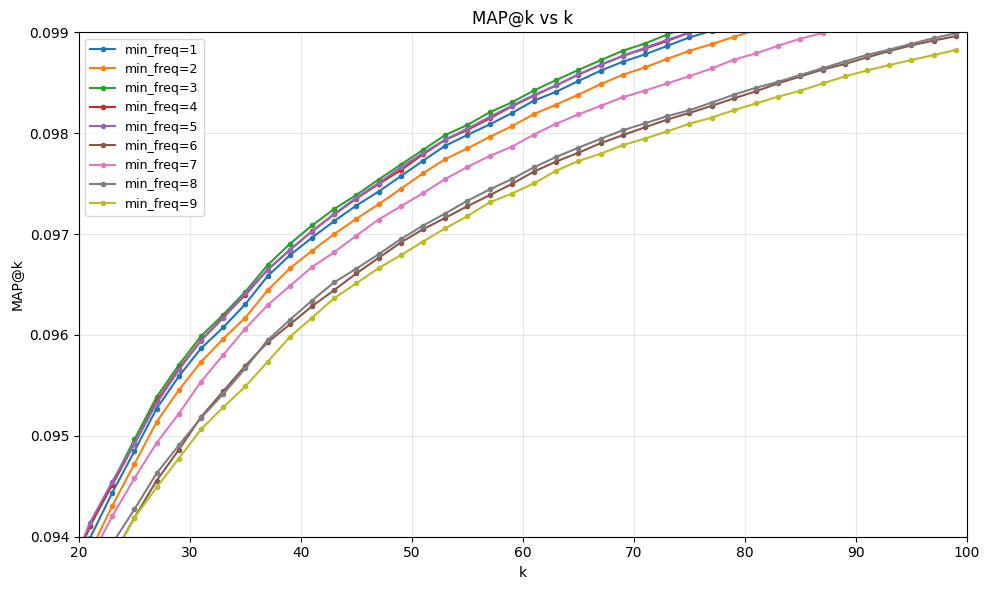

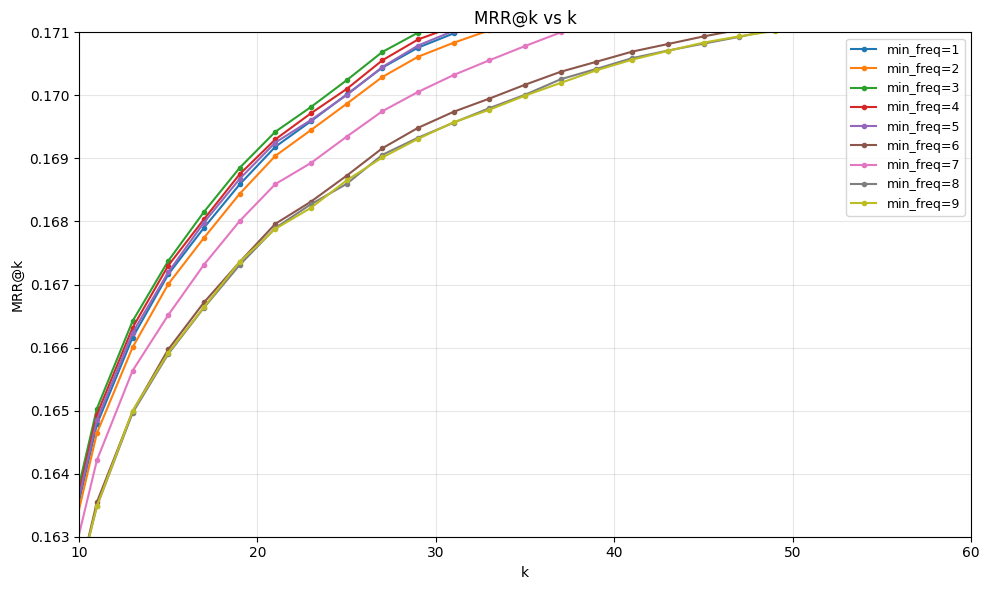

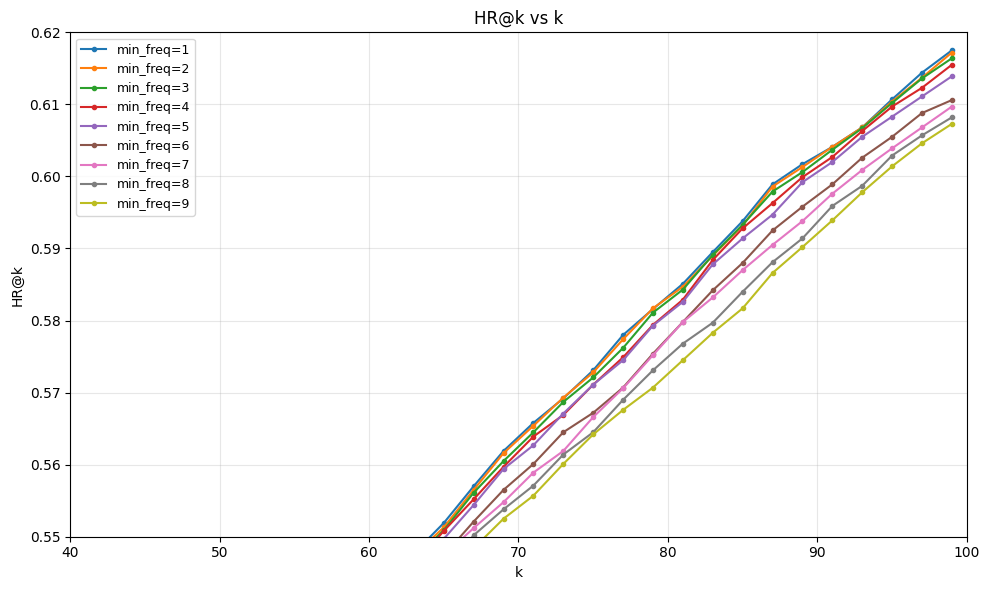

In [47]:
import matplotlib.pyplot as plt

titles = ['MAP@k', 'MRR@k', 'HR@k']

fig, ax = plt.subplots(figsize=(10, 6))
for mf in min_freqs:
    ax.plot(k_values, results[mf][0], marker='o', ms=3, label=f'min_freq={mf}')
ax.set_xlim(20, 100)
ax.set_ylim(0.094, 0.099)
ax.set_xlabel('k'); ax.set_ylabel('MAP@k')
ax.set_title('MAP@k vs k')
ax.grid(True, alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
for mf in min_freqs:
    ax.plot(k_values, results[mf][1], marker='o', ms=3, label=f'min_freq={mf}')
ax.set_xlim(10, 60)
ax.set_ylim(0.163, 0.171)
ax.set_xlabel('k'); ax.set_ylabel('MRR@k')
ax.set_title('MRR@k vs k')
ax.grid(True, alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
for mf in min_freqs:
    ax.plot(k_values, results[mf][2], marker='o', ms=3, label=f'min_freq={mf}')
ax.set_xlim(40, 100)
ax.set_ylim(0.55, 0.62)
ax.set_xlabel('k'); ax.set_ylabel('HR@k')
ax.set_title('HR@k vs k')
ax.grid(True, alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

Что вы можете сказать на основе полученных графиков? Соответствуют ли они вашим ожиданиям?

**Ответ:**

Да, качество EASE растёт с ослаблением фильтра — при min_freq=1..3 кривые MAP и MRR заметно выше, чем при min_freq=7..9, причём разрыв усиливается с ростом k. При этом HR почти не зависит от min_freq — фильтрация не мешает найти хотя бы один релевантный айтем, но заметно ухудшает его позицию (MRR) и полноту подборки (MAP).



**Задание №10. Интерпретируемые рекомендации**

Используйте выученную матрицу весов для item2item рекомендаций. Приведите 10 примеров топ-5 рекомендаций от EASE к сэмплируемым айтемам. Используйте названия фильмов вместо id при выводе рекомендаций.

In [48]:
items_df = pd.read_csv('/content/drive/MyDrive/Магистратура/2 курс/RecSys/items.csv')[['item_id','title']].copy()

def title_by_id(iid):
    t = items_df.loc[items_df.item_id == iid, 'title']
    return t.values[0] if len(t) else f'<id={iid}>'

def item2item(iid, w, item2id, id2item, top_n=5):
    idx = item2id[iid]
    scores = w[idx].copy()
    scores[idx] = -np.inf
    top = np.argsort(scores)[::-1][:top_n]
    return [(id2item[i], scores[i]) for i in top]

np.random.seed(42)
sampled = np.random.choice(list(item2id.keys()), size=10, replace=False)

w_best = fit_ease(matrix, reg_weight=best_reg_weight)

for iid in sampled:
    print(f"\n{title_by_id(iid)} (id={iid})")
    print("-" * 80)
    for rank, (rid, sc) in enumerate(item2item(iid, w_best, item2id, id2item), 1):
        print(f"  {rank}. {title_by_id(rid)[:70]:<70} {sc:+.4f}")


Ты умеешь хранить секреты? (id=5252)
--------------------------------------------------------------------------------
  1. Прабабушка легкого поведения                                           +0.0003
  2. Альфа                                                                  +0.0002
  3. Защитник                                                               +0.0002
  4. Простые сложности                                                      +0.0002
  5. История семьи Блум                                                     +0.0002

Море соблазна (id=15244)
--------------------------------------------------------------------------------
  1. Комната желаний                                                        +0.0006
  2. Зелёная книга                                                          +0.0006
  3. Во власти стихии                                                       +0.0005
  4. Аферистка                                                              +0.0005
  5. Линкольн для 

Хорошие ли получились рекомендации? Почему? Есть ли хорошие примеры? Есть ли плохие? Почему бывают плохие примеры?

**Ответ:**
Рекомендации в основном осмысленные: для популярных фильмов с чёткой аудиторией EASE выдаёт тематически близкие примеры (Логан → другие «Люди Икс», Пациент Зеро → ужасы, Срочная доставка → боевики). Плохие примеры бывают у разреженных или мультиаудиторных айтемов (Фунтик → «Гнев человеческий») — из-за популярностного сдвига и того, что EASE не знает контента, а опирается только на совместные просмотры.